In [2]:
#IMPORT LIBS
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import cartopy.crs as ccrs
from datetime import timedelta
import cartopy.util as cutil
import pandas as pd
#import statsmodels.api as sm
from tqdm import tqdm

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


### Uploading CMIP6 dictionaries 

In [6]:
'''
Importing CMIP6 dictionaries
'''
CMIP6_dics = []
# Path to the dataset directory
dictionaries_path = "/emmy-noether/home/mf671/github/greenland_blocking/numpy_dictionaries/CMIP6_hist/"

# List all files
dic_file_list = [
    f for f in os.listdir(dictionaries_path)
    if os.path.isfile(os.path.join(dictionaries_path, f)) and 'DAV' in f
]

dic_file_list = sorted(dic_file_list) #just for security

for i in tqdm(range(len(dic_file_list))[:]):
    #print(dictionaries_path + dic_file_list[i])
    CMIP6_dics.append(np.load(dictionaries_path + dic_file_list[i],allow_pickle=True))

100%|█████████████████████████████████████████████████████████████████████| 120/120 [00:08<00:00, 14.86it/s]


### Uploading CMIP6 future dictionary

In [8]:
'''
Importing CMIP6 dictionaries
'''
CMIP6_future_dics = []
# Path to the dataset directory
dictionaries_path = "/emmy-noether/home/mf671/github/greenland_blocking/numpy_dictionaries/CMIP6_future/"

# List all files
dic_file_list = [
    f for f in os.listdir(dictionaries_path)
    if os.path.isfile(os.path.join(dictionaries_path, f)) and 'DAV' in f
]

dic_file_list = sorted(dic_file_list) #just for security

for i in tqdm(range(len(dic_file_list))[:]):
    #print(dictionaries_path + dic_file_list[i])
    CMIP6_future_dics.append(np.load(dictionaries_path + dic_file_list[i],allow_pickle=True))

100%|███████████████████████████████████████████████████████████████████████| 63/63 [00:02<00:00, 21.61it/s]


### Plotting BOXPLOTS

In [9]:
def get_distribution_from_dics_list(dics,key_name,block_type='all'):
    population = []
    for model_dic in dics:
        for element in model_dic:
            if block_type == 'upstream':
                if sum(element['WBI'])/len(element['WBI']) > 0:
                    continue
            if block_type == 'retrograding':
                if sum(element['WBI'])/len(element['WBI']) <= 0:
                    continue
            try:
                population.append(sum(element[key_name])/len(element[key_name]))
            except:
                #print(element[key_name])
                population.append(element[key_name])    
    return population
def get_distribution_from_dic(dic,key_name,block_type='all'):
    population = []
    for element in dic:
        if block_type == 'upstream':
            if sum(element['WBI'])/len(element['WBI']) > 0:
                continue
        if block_type == 'retrograding':
            if sum(element['WBI'])/len(element['WBI']) <= 0:
                continue
        try:
            population.append(sum(element[key_name])/len(element[key_name]))
        except:
            #print('no list!')
            population.append(element[key_name])
    return population

def plot_distr(ax,var1,var2,hist_range,xlabel):
    ax.hist(var1,bins=20,range=hist_range,density = True,alpha=0.4,color='orange')
    ax.hist(var2,bins=20,range=hist_range,density = True,alpha=0.4,color='blue')
    ax.axvline(x=np.mean(np.array(var1)), color='orange',label='hist.')#, linestyle='STYLE', linewidth=WIDTH)
    ax.axvline(x=np.mean(np.array(var2)), color='blue',label='fut.')#, linestyle='STYLE', linewidth=WIDTH)
    ax.legend(fontsize='small')
    ax.set_ylabel('probability density [unitless]')
    ax.set_xlabel(xlabel)
        

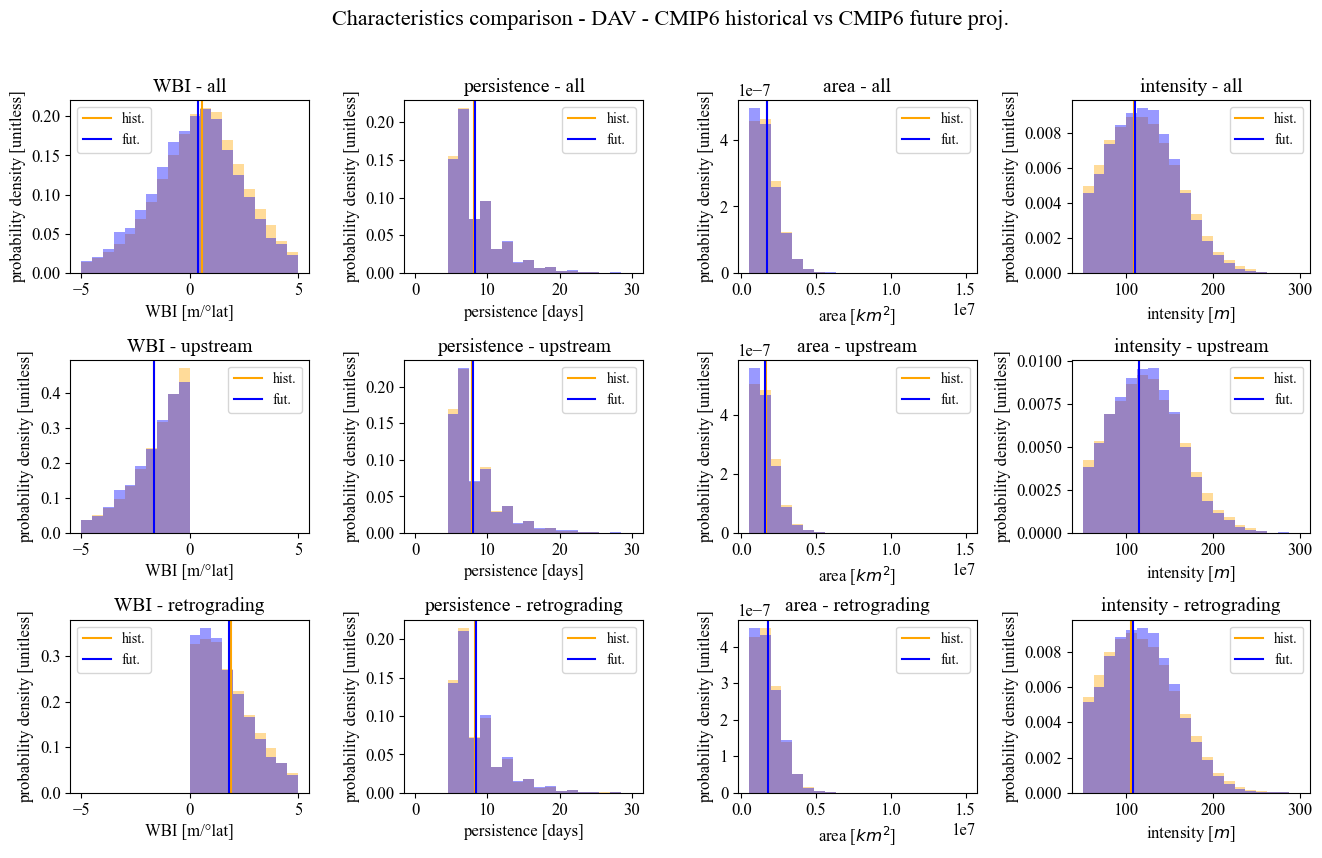

In [10]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 9))
fig.subplots_adjust(wspace=0.4,hspace=0.5)
axes = axes.flatten()

plt.suptitle('Characteristics comparison - DAV - CMIP6 historical vs CMIP6 future proj.',fontsize=16)


WBIS_hist = get_distribution_from_dics_list(CMIP6_dics,'WBI')
WBIS_future = get_distribution_from_dics_list(CMIP6_future_dics,'WBI')

persistences_hist = get_distribution_from_dics_list(CMIP6_dics,'persistence')
persistences_future = get_distribution_from_dics_list(CMIP6_future_dics,'persistence')

areas_hist = get_distribution_from_dics_list(CMIP6_dics,'area')
areas_future = get_distribution_from_dics_list(CMIP6_future_dics,'area')

intensitys_hist = get_distribution_from_dics_list(CMIP6_dics,'intensity')
intensitys_future = get_distribution_from_dics_list(CMIP6_future_dics,'intensity')

axes[0].set_title('WBI - all')
plot_distr(axes[0],WBIS_hist,WBIS_future,[-5,5],'WBI [m/°lat]')

axes[1].set_title('persistence - all')
plot_distr(axes[1],persistences_hist,persistences_future,[0,30],'persistence [days]')

axes[2].set_title('area - all')
plot_distr(axes[2],areas_hist,areas_future,[5e5,1.5e7],r'area [$km^2$]')

axes[3].set_title('intensity - all')
plot_distr(axes[3],intensitys_hist,intensitys_future,[50,300],r'intensity [$m$]')

WBIS_hist = get_distribution_from_dics_list(CMIP6_dics,'WBI',block_type='upstream')
WBIS_future = get_distribution_from_dics_list(CMIP6_future_dics,'WBI',block_type='upstream')

persistences_hist = get_distribution_from_dics_list(CMIP6_dics,'persistence',block_type='upstream')
persistences_future = get_distribution_from_dics_list(CMIP6_future_dics,'persistence',block_type='upstream')

areas_hist = get_distribution_from_dics_list(CMIP6_dics,'area',block_type='upstream')
areas_future = get_distribution_from_dics_list(CMIP6_future_dics,'area',block_type='upstream')

intensitys_hist = get_distribution_from_dics_list(CMIP6_dics,'intensity',block_type='upstream')
intensitys_future = get_distribution_from_dics_list(CMIP6_future_dics,'intensity',block_type='upstream')

axes[4].set_title('WBI - upstream')
plot_distr(axes[4],WBIS_hist,WBIS_future,[-5,5],'WBI [m/°lat]')

axes[5].set_title('persistence - upstream')
plot_distr(axes[5],persistences_hist,persistences_future,[0,30],'persistence [days]')

axes[6].set_title('area - upstream')
plot_distr(axes[6],areas_hist,areas_future,[5e5,1.5e7],r'area [$km^2$]')

axes[7].set_title('intensity - upstream')
plot_distr(axes[7],intensitys_hist,intensitys_future,[50,300],r'intensity [$m$]')

WBIS_hist = get_distribution_from_dics_list(CMIP6_dics,'WBI',block_type='retrograding')
WBIS_future = get_distribution_from_dics_list(CMIP6_future_dics,'WBI',block_type='retrograding')

persistences_hist = get_distribution_from_dics_list(CMIP6_dics,'persistence',block_type='retrograding')
persistences_future = get_distribution_from_dics_list(CMIP6_future_dics,'persistence',block_type='retrograding')

areas_hist = get_distribution_from_dics_list(CMIP6_dics,'area',block_type='retrograding')
areas_future = get_distribution_from_dics_list(CMIP6_future_dics,'area',block_type='retrograding')

intensitys_hist = get_distribution_from_dics_list(CMIP6_dics,'intensity',block_type='retrograding')
intensitys_future = get_distribution_from_dics_list(CMIP6_future_dics,'intensity',block_type='retrograding')

axes[8].set_title('WBI - retrograding')
plot_distr(axes[8],WBIS_hist,WBIS_future,[-5,5],'WBI [m/°lat]')

axes[9].set_title('persistence - retrograding')
plot_distr(axes[9],persistences_hist,persistences_future,[0,30],'persistence [days]')

axes[10].set_title('area - retrograding')
plot_distr(axes[10],areas_hist,areas_future,[5e5,1.5e7],r'area [$km^2$]')

axes[11].set_title('intensity - retrograding')
plot_distr(axes[11],intensitys_hist,intensitys_future,[50,300],r'intensity [$m$]')

plt.savefig('PLOTS/FigureS5.png',dpi=300)